In [2]:
import numpy as np
import matplotlib.pyplot as plt
from DistanceProject import DistanceAnalysis, create_new_result_dir
from DistancePlots import plot_repeats, plot_trials, plot_raw_traces, plot_trials_ordered, plot_reliability_distribution, plot_trials_ordered_2, plot_boxplot, plot_RF_vs_modulation
import os
import pickle

data_dir = r'D:/data-distance-coding-project/processed-data'

In [26]:
imaging_filename = r'240731_SAM019_1'
imaging_dir = os.path.join(data_dir, imaging_filename)
object_filename = imaging_dir + '/' + imaging_filename + '_distance_spikes.pkl'

if os.path.exists(object_filename):
    with open(object_filename, 'rb') as f:
        D = pickle.load(f)
        print('Loaded DistanceAnalysis object')

Loaded DistanceAnalysis object


In [113]:
# get the cells where is reliable one eye and two eye
reliable = np.where(np.array(D.stats['type']) != 'un-reliable')[0]
stimuli = np.linspace(0, 1, 100)

resp_all = []
for cell in reliable:
    resp_all.append(D.get_all_traces(cell, mean_trace=True)[0])

resp_all = np.array(resp_all).T
n_stimuli, n_neurons = resp_all.shape
print('Number of neurons: ' + str(n_neurons))
print('Number of stimuli: ' + str(n_stimuli))

[0.         0.01010101 0.02020202 0.03030303 0.04040404 0.05050505
 0.06060606 0.07070707 0.08080808 0.09090909 0.1010101  0.11111111
 0.12121212 0.13131313 0.14141414 0.15151515 0.16161616 0.17171717
 0.18181818 0.19191919 0.2020202  0.21212121 0.22222222 0.23232323
 0.24242424 0.25252525 0.26262626 0.27272727 0.28282828 0.29292929
 0.3030303  0.31313131 0.32323232 0.33333333 0.34343434 0.35353535
 0.36363636 0.37373737 0.38383838 0.39393939 0.4040404  0.41414141
 0.42424242 0.43434343 0.44444444 0.45454545 0.46464646 0.47474747
 0.48484848 0.49494949 0.50505051 0.51515152 0.52525253 0.53535354
 0.54545455 0.55555556 0.56565657 0.57575758 0.58585859 0.5959596
 0.60606061 0.61616162 0.62626263 0.63636364 0.64646465 0.65656566
 0.66666667 0.67676768 0.68686869 0.6969697  0.70707071 0.71717172
 0.72727273 0.73737374 0.74747475 0.75757576 0.76767677 0.77777778
 0.78787879 0.7979798  0.80808081 0.81818182 0.82828283 0.83838384
 0.84848485 0.85858586 0.86868687 0.87878788 0.88888889 0.89898

In [65]:
# Load data
import torch
from torch import nn
from torch import optim

In [114]:
# Set random seeds for reproducibility
np.random.seed(4)
torch.manual_seed(4)

# Split data into training set and testing set
n_train = int(0.6 * n_stimuli)  # use 60% of all data for training set
ishuffle = torch.randperm(n_stimuli)
itrain = ishuffle[:n_train]  # indices of data samples to include in training set
itest = ishuffle[n_train:]  # indices of data samples to include in testing set
stimuli_test = stimuli[itest]
resp_test = resp_all[itest]
stimuli_train = stimuli[itrain]
resp_train = resp_all[itrain]

In [41]:
class DeepNet(nn.Module):
  """Deep Network with one hidden layer

  Args:
    n_inputs (int): number of input units
    n_hidden (int): number of units in hidden layer

  Attributes:
    in_layer (nn.Linear): weights and biases of input layer
    out_layer (nn.Linear): weights and biases of output layer

  """

  def __init__(self, n_inputs, n_hidden):
    super().__init__()  # needed to invoke the properties of the parent class nn.Module
    self.in_layer = nn.Linear(n_inputs, n_hidden) # neural activity --> hidden units
    self.out_layer = nn.Linear(n_hidden, 1) # hidden units --> output

  def forward(self, r):
    """Decode stimulus orientation from neural responses

    Args:
      r (torch.Tensor): vector of neural responses to decode, must be of
        length n_inputs. Can also be a tensor of shape n_stimuli x n_inputs,
        containing n_stimuli vectors of neural responses

    Returns:
      torch.Tensor: network outputs for each input provided in r. If
        r is a vector, then y is a 1D tensor of length 1. If r is a 2D
        tensor then y is a 2D tensor of shape n_stimuli x 1.

    """
    h = self.in_layer(r)  # hidden representation
    y = self.out_layer(h)
    return y


In [54]:
class DeepNetReLU(nn.Module):
  """ network with a single hidden layer h with a RELU """

  def __init__(self, n_inputs, n_hidden):
    super().__init__()  # needed to invoke the properties of the parent class nn.Module
    self.in_layer = nn.Linear(n_inputs, n_hidden) # neural activity --> hidden units
    self.out_layer = nn.Linear(n_hidden, 1) # hidden units --> output

  def forward(self, r):

    h = self.in_layer(r)  # hidden representation
    h = torch.relu(h)  # rectified linear activation function
    y = self.out_layer(h)

    return y

decoded orientation: 2.49 degrees
true orientation: -6.67 degrees


In [77]:
def get_data(n_stim, train_data, train_labels):
  """ Return n_stim randomly drawn stimuli/resp pairs

  Args:
    n_stim (scalar): number of stimuli to draw
    resp (torch.Tensor):
    train_data (torch.Tensor): n_train x n_neurons tensor with neural
      responses to train on
    train_labels (torch.Tensor): n_train x 1 tensor with orientations of the
      stimuli corresponding to each row of train_data, in radians

  Returns:
    (torch.Tensor, torch.Tensor): n_stim x n_neurons tensor of neural responses and n_stim x 1 of orientations respectively
  """
  n_stimuli = train_labels.shape[0]
  istim = np.random.choice(n_stimuli, n_stim)
  r = train_data[istim]  # neural responses to this stimulus
  ori = train_labels[istim]  # true stimulus orientation

  return r, ori

In [79]:
# Set random seeds for reproducibility
np.random.seed(1)
torch.manual_seed(1)

# Initialize a deep network with M=200 hidden units
net = DeepNetReLU(n_neurons, 200)

# Get neural responses (r) to and orientation (ori) to one stimulus in dataset
r, ori = get_data(1, resp_train, stimuli_train)  # using helper function get_data

# Decode orientation from these neural responses using initialized network
out = net(torch.Tensor(r))  # compute output from network, equivalent to net.forward(r)

print(f'decoded orientation: {out.item():.2f} degrees')
print(f'true orientation: {ori.item():.2f} degrees')

decoded orientation: 2.49 degrees
true orientation: -6.67 degrees


In [91]:
np.random.seed(1)
torch.manual_seed(1)

# Initialize a deep network with M=10 hidden units
net = DeepNetReLU(n_neurons, 10)

# Get neural responses to first 20 stimuli in the data set
r, ori = get_data(20, resp_train, stimuli_train)

print(r.shape)
print(ori.shape)

# Decode orientation from these neural responses
out = np.squeeze(net(torch.Tensor(r)))
ori = torch.Tensor(ori)


# # Initialize PyTorch mean squared error loss function (Hint: look at nn.MSELoss)
loss_fn = nn.MSELoss()

# # Evaluate mean squared error
loss = loss_fn(out, ori)

print(f'mean squared error: {loss:.2f}')

(20, 350)
(20,)
mean squared error: 806.91


In [93]:
def train(net, loss_fn, train_data, train_labels,
          n_epochs=50, learning_rate=1e-4):
    """Run gradient descent to optimize parameters of a given network

    Args:
      net (nn.Module): PyTorch network whose parameters to optimize
      loss_fn: built-in PyTorch loss function to minimize
      train_data (torch.Tensor): n_train x n_neurons tensor with neural
        responses to train on
      train_labels (torch.Tensor): n_train x 1 tensor with orientations of the
        stimuli corresponding to each row of train_data
      n_epochs (int, optional): number of epochs of gradient descent to run
      learning_rate (float, optional): learning rate to use for gradient descent

    Returns:
      (list): training loss over iterations

    """

    # Initialize PyTorch SGD optimizer
    optimizer = optim.SGD(net.parameters(), lr=learning_rate)

    # Placeholder to save the loss at each iteration
    train_loss = []

    # Loop over epochs
    for i in range(n_epochs):
        # compute network output from inputs in train_data
        out = net(train_data)  # Forward pass

        # evaluate loss function
        loss = loss_fn(out, train_labels)

        # Clear previous gradients
        optimizer.zero_grad()

        # Compute gradients
        loss.backward()

        # Update weights
        optimizer.step()

        # Store current value of loss
        train_loss.append(loss.item())  # .item() needed to transform the tensor output of loss_fn to a scalar

        # Track progress
        if (i + 1) % (n_epochs // 5) == 0:
            print(f'iteration {i + 1}/{n_epochs} | loss: {loss.item():.3f}')

    return train_loss

In [94]:
def plot_train_loss(train_loss):
  plt.plot(train_loss)
  plt.xlim([0, None])
  plt.ylim([0, None])
  plt.xlabel('iterations of gradient descent')
  plt.ylabel('mean squared error')
  plt.show()

iteration 10/50 | loss: 4.886
iteration 20/50 | loss: 0.899
iteration 30/50 | loss: 0.351
iteration 40/50 | loss: 0.195
iteration 50/50 | loss: 0.136


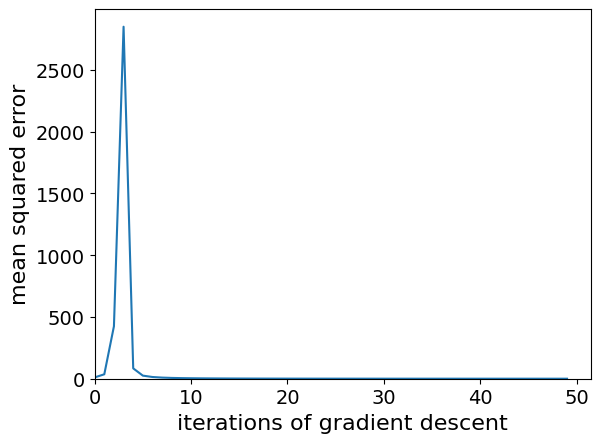

In [115]:
# Set random seeds for reproducibility
np.random.seed(1)
torch.manual_seed(1)

# Initialize network with 10 hidden units
net = DeepNetReLU(n_neurons, 350)

# Initialize built-in PyTorch MSE loss function
loss_fn = nn.MSELoss()

# Run gradient descent on data
train_loss = train(net, loss_fn, np.squeeze(torch.Tensor(resp_train)), torch.Tensor(stimuli_train))

# Plot the training loss over iterations of GD
plot_train_loss(train_loss)

In [116]:
# evalue the network on all the data
out = np.squeeze(net(torch.Tensor(resp_test)))
ori = torch.Tensor(stimuli_test)
loss = loss_fn(out, ori)
print(f'mean squared error: {loss:.2f}')

mean squared error: 0.11


In [118]:
print(out)
print(ori)

tensor([0.6081, 0.4710, 0.5263, 0.6471, 0.5505, 0.6546, 0.7521, 0.4013, 0.7957,
        0.4857, 0.7977, 0.8127, 0.6505, 0.6623, 0.5780, 0.4347, 0.7226, 0.5557,
        0.3235, 0.9716, 0.7177, 0.8157, 0.6368, 0.7767, 0.5037, 0.6511, 0.7487,
        0.4779, 0.6562, 0.5021, 0.7838, 0.7369, 0.5949, 0.7849, 0.6094, 0.7162,
        0.6000, 0.3235, 0.7713, 0.5097], grad_fn=<SqueezeBackward0>)
tensor([0.0404, 0.1919, 0.2828, 0.3535, 0.5556, 0.3232, 0.6465, 0.9899, 0.7778,
        0.5859, 0.7879, 0.8182, 0.4040, 0.0505, 0.3131, 0.9798, 0.7273, 0.9596,
        0.0202, 0.5152, 0.4545, 0.1111, 0.4343, 0.8889, 0.0303, 0.4141, 0.8384,
        0.5657, 0.9394, 0.9697, 0.8788, 0.0606, 0.2626, 0.8283, 0.3939, 0.4646,
        0.9495, 0.0101, 0.7677, 0.1818])


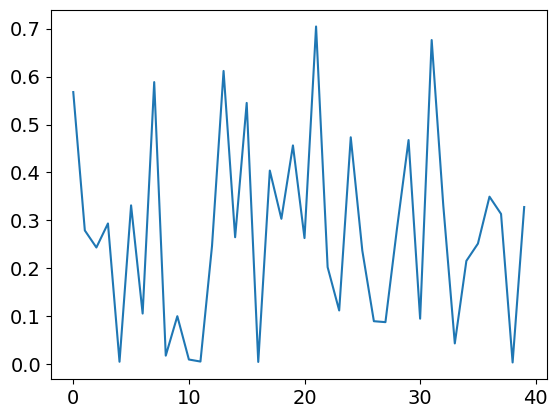

In [120]:
# print the error for every orientation
error = np.abs(out.detach().numpy() - ori.numpy())
plt.plot(error)
